In [5]:
import noisereduce as nr
import librosa
import soundfile as sf
import numpy as np

# 1. Load file
data, rate = librosa.load('audio.wav', sr=None)

# 2. Thực hiện lọc nhiễu
reduced_noise = nr.reduce_noise(
    y=data, 
    sr=rate, 
    stationary=False,        # Do nhiễu không ổn định (xe cộ, tiếng ồn đường phố)
    prop_decrease=0.85,      # Giữ lại 15% nhiễu để giọng tự nhiên
)

# 3. Tính RMS
rms_original = np.sqrt(np.mean(data**2))
rms_reduced = np.sqrt(np.mean(reduced_noise**2))

# 4. RMS Matching
reduced_noise_matched = reduced_noise * (rms_original / rms_reduced)

# 5. Xuất file
sf.write("audio_filtered.wav", reduced_noise_matched, rate)

In [ ]:
import numpy as np

print(np.sqrt(np.mean(data**2)))    # RMS của file gốc
print(np.sqrt(np.mean(reduced_noise_matched**2)))   # RMS của file đã lọc (sau khi đã RMS Matching)

0.04305583
0.04305583


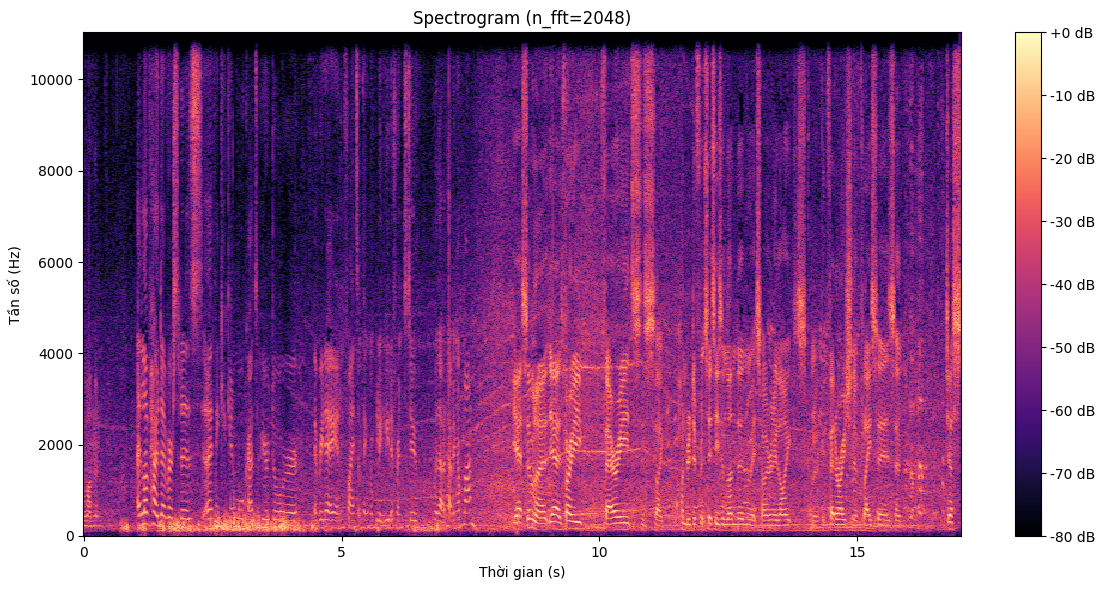

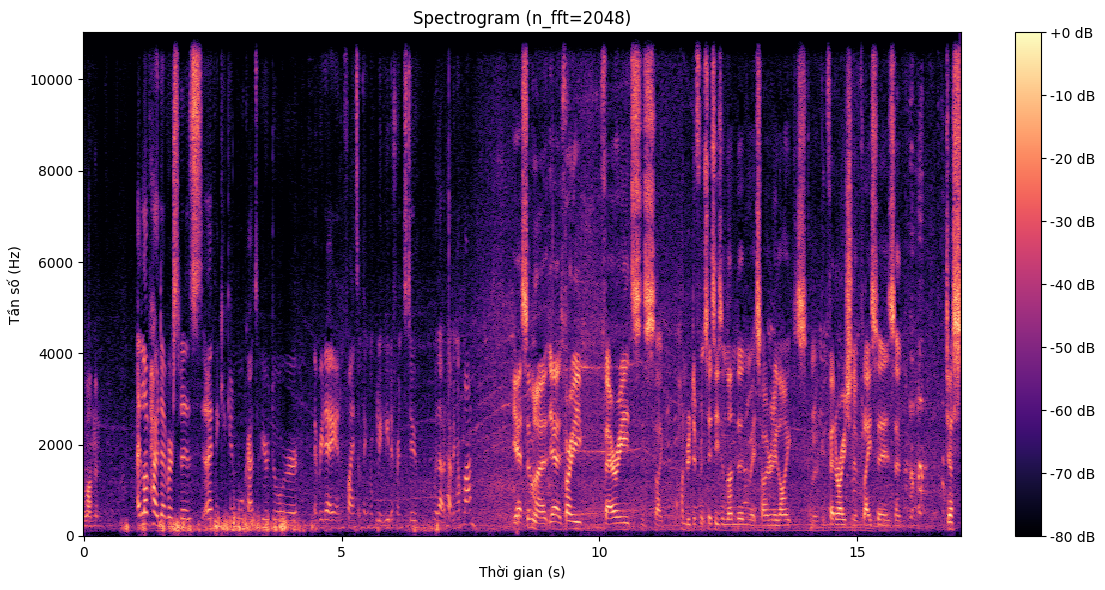

In [2]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

def plot_spectrogram(file_path, n_fft=2048):
    y, sr = librosa.load(file_path)
    stft = librosa.stft(y, n_fft=n_fft, hop_length=n_fft//4)
    s_db = librosa.amplitude_to_db(np.abs(stft), ref=np.max)
    plt.figure(figsize=(12, 6))
    librosa.display.specshow(s_db, sr=sr, hop_length=n_fft//4, 
                             x_axis='time', y_axis='hz', cmap='magma')
    plt.colorbar(format='%+2.0f dB')
    plt.title(f'Spectrogram (n_fft={n_fft})')
    plt.xlabel('Thời gian (s)')
    plt.ylabel('Tần số (Hz)')
    plt.tight_layout()
    plt.savefig(f'spectrogram_{file_path.split(".")[0]}.png')
    plt.show()
    
plot_spectrogram("audio.wav")
plot_spectrogram("audio_filtered.wav")